# Figure 7 — plotting

This notebook reads only validated tables written by
`01_Figure7_Analysis.ipynb`. The final figure contains five evidence-bearing
panels: experimental design, PCA, score trajectories, formal contrasts, and
matched-null specificity. The draft interpretation schematic is retained in
the manuscript text rather than presented as an additional data panel.


In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    os.environ.get("MITOXY_PROJECT_ROOT", "/scratch/ar58064/mitoxy")
).resolve()
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "gse235046"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "figure_7_clean"
FIGURE_DIR = PROJECT_ROOT / "figures" / "figure_7_clean"
for directory in [RAW_DIR, OUTPUT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)


Project root: /scratch/ar58064/mitoxy


In [2]:
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelcolor": "#283544",
    "xtick.color": "#4F5B6A",
    "ytick.color": "#4F5B6A",
    "axes.edgecolor": "#8793A1",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

NAVY = "#1E2732"
BLUE = "#087EBD"
ORANGE = "#E36A00"
TEAL = "#00A67E"
PURPLE = "#8053A6"
GRAY = "#687587"
LIGHT = "#F3F6F9"
GRID = "#DDE4EA"


def read_panel(name, columns):
    path = OUTPUT_DIR / name
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Run 01_Figure7_Analysis.ipynb first."
        )
    table = pd.read_csv(path)
    missing = sorted(set(columns) - set(table.columns))
    if missing:
        raise KeyError(f"{path.name} is missing columns: {missing}")
    return table


panel_b = read_panel(
    "panel_b_pca.csv",
    ["sample_id", "condition", "pc1", "pc2", "pc1_variance_pct", "pc2_variance_pct"],
)
panel_c = read_panel(
    "panel_c_score_trajectories.csv",
    ["score", "condition", "mean", "sem"],
)
panel_d = read_panel(
    "panel_d_contrasts.csv",
    ["score", "contrast", "effect", "ci_low", "ci_high", "p_value"],
)
panel_e = read_panel(
    "panel_e_specificity.csv",
    ["contrast", "percentile", "empirical_p", "joint_empirical_p", "n_modules"],
)


def panel_letter(ax, letter, x=-0.06, y=1.08):
    ax.text(
        x, y, letter, transform=ax.transAxes,
        fontsize=23, fontweight="bold", color=NAVY,
        ha="left", va="top", clip_on=False,
    )


def clean_axis(ax, grid_axis="x"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#9AA5B1")
    ax.spines["bottom"].set_color("#9AA5B1")
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)


def p_text(value):
    if value < 0.001:
        return f"P = {value:.1e}"
    return f"P = {value:.3f}"


## Assemble the final five-panel figure


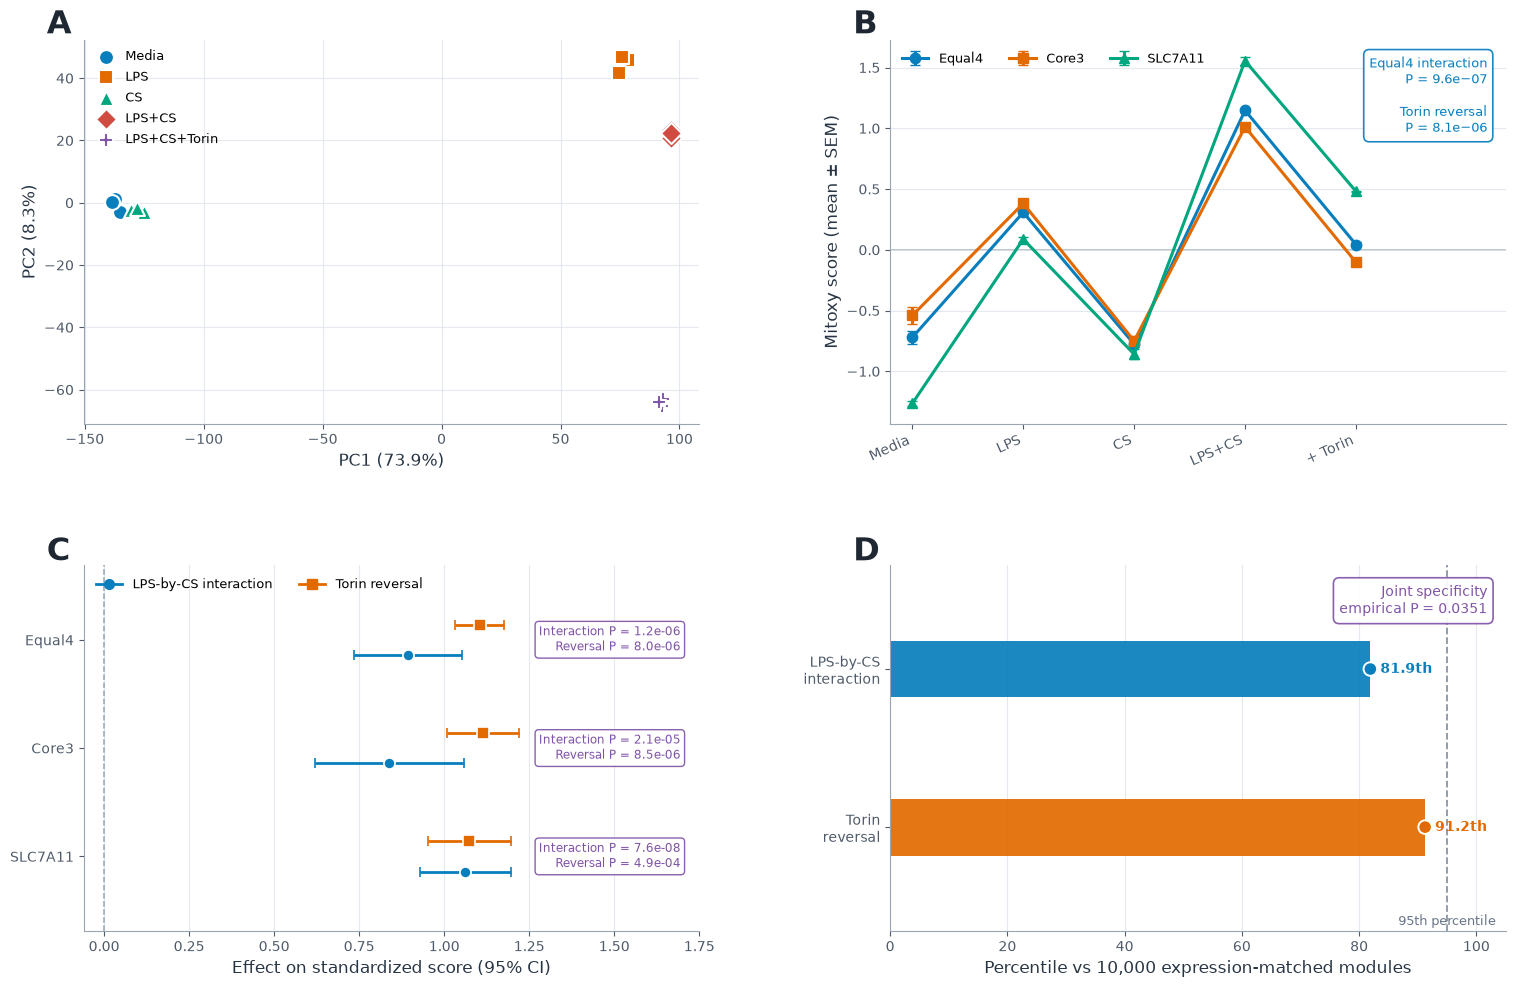

Saved:
/scratch/ar58064/mitoxy/figures/figure_7_clean/Figure_7_final.png
/scratch/ar58064/mitoxy/figures/figure_7_clean/Figure_7_final.svg
/scratch/ar58064/mitoxy/figures/figure_7_clean/Figure_7_final.pdf


In [4]:
fig = plt.figure(figsize=(15.8, 14.4), constrained_layout=False)
grid = fig.add_gridspec(
    3, 2, height_ratios=[0.72, 1.05, 1.0],
    left=0.075, right=0.975, top=0.97, bottom=0.07,
    hspace=0.42, wspace=0.31,
)
ax_b = fig.add_subplot(grid[1, 0])
ax_c = fig.add_subplot(grid[1, 1])
ax_d = fig.add_subplot(grid[2, 0])
ax_e = fig.add_subplot(grid[2, 1])

# ------------------------------------------------------------------
# B — PCA
# ------------------------------------------------------------------
panel_letter(ax_b, "A")
condition_style = {
    "Media": (BLUE, "o"),
    "LPS": (ORANGE, "s"),
    "CS": (TEAL, "^"),
    "LPS+CS": ("#D04B40", "D"),
    "LPS+CS+Torin": (PURPLE, "P"),
}
for condition, (color, marker) in condition_style.items():
    subset = panel_b.loc[panel_b["condition"].eq(condition)]
    ax_b.scatter(
        subset["pc1"], subset["pc2"], s=115, marker=marker,
        color=color, edgecolor="white", linewidth=1.5, label=condition, zorder=3,
    )
pc1_pct = panel_b["pc1_variance_pct"].iloc[0]
pc2_pct = panel_b["pc2_variance_pct"].iloc[0]
ax_b.set_xlabel(f"PC1 ({pc1_pct:.1f}%)", fontsize=12)
ax_b.set_ylabel(f"PC2 ({pc2_pct:.1f}%)", fontsize=12)
clean_axis(ax_b, grid_axis="both")
ax_b.legend(
    frameon=False, loc="upper left", fontsize=9.5,
    handletextpad=0.45, borderpad=0.2, ncol=1,
)

# ------------------------------------------------------------------
# C — score trajectories
# ------------------------------------------------------------------
panel_letter(ax_c, "B")
score_style = {
    "Equal4": (BLUE, "o"),
    "Core3": (ORANGE, "s"),
    "SLC7A11": (TEAL, "^"),
}
conditions = ["Media", "LPS", "CS", "LPS+CS", "LPS+CS+Torin"]
x = np.arange(len(conditions))
for score_name, (color, marker) in score_style.items():
    subset = panel_c.loc[panel_c["score"].eq(score_name)].copy()
    subset["condition"] = pd.Categorical(
        subset["condition"], categories=conditions, ordered=True
    )
    subset = subset.sort_values("condition")
    ax_c.errorbar(
        x, subset["mean"], yerr=subset["sem"],
        color=color, marker=marker, markersize=7.5,
        linewidth=2.2, capsize=3.5, label=score_name, zorder=3,
    )
ax_c.axhline(0, color="#AAB4BF", linewidth=1.1, zorder=0)
ax_c.set_xticks(x, ["Media", "LPS", "CS", "LPS+CS", "+ Torin"], rotation=24, ha="right")
ax_c.set_xlim(-0.20, 5.35)
ax_c.set_ylabel("Mitoxy score (mean ± SEM)", fontsize=12)
clean_axis(ax_c, grid_axis="y")
ax_c.legend(frameon=False, loc="upper left", ncol=3, fontsize=9.5)
ax_c.text(
    0.97, 0.96,
    "Equal4 interaction\nP = 9.6e−07\n\nTorin reversal\nP = 8.1e−06",
    transform=ax_c.transAxes, ha="right", va="top",
    fontsize=9.5, color=BLUE,
    bbox=dict(boxstyle="round,pad=0.42", facecolor="white", alpha=0.92,
              edgecolor=BLUE, linewidth=1.2),
)

# ------------------------------------------------------------------
# D — contrast forest
# ------------------------------------------------------------------
panel_letter(ax_d, "C")
scores_order = ["Equal4", "Core3", "SLC7A11"]
contrasts = ["LPS-by-CS interaction", "Torin reversal"]
offsets = {contrasts[0]: 0.14, contrasts[1]: -0.14}
colors = {contrasts[0]: BLUE, contrasts[1]: ORANGE}
markers = {contrasts[0]: "o", contrasts[1]: "s"}
for contrast in contrasts:
    subset = panel_d.loc[panel_d["contrast"].eq(contrast)]
    for _, row in subset.iterrows():
        base = scores_order.index(row["score"])
        y = base + offsets[contrast]
        ax_d.errorbar(
            row["effect"], y,
            xerr=[[row["effect"] - row["ci_low"]],
                  [row["ci_high"] - row["effect"]]],
            fmt=markers[contrast], color=colors[contrast],
            markersize=8, elinewidth=2.0, capsize=3.5,
            markeredgecolor="white", markeredgewidth=1.2, zorder=3,
        )
ax_d.set_yticks(range(len(scores_order)), scores_order)
ax_d.invert_yaxis()
ax_d.axvline(0, color="#98A4AF", linestyle="--", linewidth=1.1)
ax_d.set_xlim(-0.06, 1.75)
ax_d.set_xlabel("Effect on standardized score (95% CI)", fontsize=12)
clean_axis(ax_d, grid_axis="x")
legend_handles = [
    Line2D([0], [0], marker=markers[c], color=colors[c], lw=2,
           markersize=7, label=c) for c in contrasts
]
ax_d.legend(
    handles=legend_handles, frameon=False, loc="upper left",
    fontsize=9.5, ncol=2,
)
ax_d.margins(y=0.24)

# Add compact, non-overlapping P-value boxes in the right margin of the axis.
x_min, x_max = ax_d.get_xlim()
label_x = x_min + 0.97 * (x_max - x_min)
for base, score_name in enumerate(scores_order):
    rows = panel_d.loc[panel_d["score"].eq(score_name)].set_index("contrast")
    text_value = (
        f"Interaction {p_text(rows.loc[contrasts[0], 'p_value'])}\n"
        f"Reversal {p_text(rows.loc[contrasts[1], 'p_value'])}"
    )
    ax_d.text(
        label_x, base, text_value, ha="right", va="center",
        fontsize=8.4, color=PURPLE,
        bbox=dict(boxstyle="round,pad=0.32", facecolor="white", alpha=0.92,
                  edgecolor=PURPLE, linewidth=1.0),
    )

# ------------------------------------------------------------------
# E — matched-null specificity
# ------------------------------------------------------------------
panel_letter(ax_e, "D")
e = panel_e.set_index("contrast")
labels = ["LPS-by-CS\ninteraction", "Torin\nreversal"]
values = [
    e.loc["LPS-by-CS interaction", "percentile"],
    e.loc["Torin reversal", "percentile"],
]
bar_colors = [BLUE, ORANGE]
y = np.arange(2)
ax_e.barh(y, values, height=0.36, color=bar_colors, alpha=0.92, zorder=2)
ax_e.scatter(values, y, s=95, color=bar_colors, edgecolor="white", linewidth=1.4, zorder=3)
ax_e.axvline(95, color="#8995A2", linestyle="--", linewidth=1.3)
ax_e.text(95, 1.55, "95th percentile", ha="center", va="top", fontsize=9, color=GRAY)
for yi, value, color in zip(y, values, bar_colors):
    ax_e.text(
        min(value + 1.7, 97.8), yi, f"{value:.1f}th",
        va="center", ha="left", fontsize=10, fontweight="bold", color=color,
    )
ax_e.set_yticks(y, labels)
ax_e.invert_yaxis()
ax_e.set_xlim(0, 105)
ax_e.set_xlabel("Percentile vs 10,000 expression-matched modules", fontsize=12)
clean_axis(ax_e, grid_axis="x")
joint_p = panel_e["joint_empirical_p"].iloc[0]
ax_e.text(
    0.97, 0.95,
    f"Joint specificity\nempirical P = {joint_p:.4f}",
    transform=ax_e.transAxes, ha="right", va="top",
    fontsize=10, color=PURPLE,
    bbox=dict(boxstyle="round,pad=0.42", facecolor="white", alpha=0.92,
              edgecolor=PURPLE, linewidth=1.2),
)
ax_e.margins(y=0.35)

png_path = FIGURE_DIR / "Figure_7_final.png"
svg_path = FIGURE_DIR / "Figure_7_final.svg"
pdf_path = FIGURE_DIR / "Figure_7_final.pdf"
fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("Saved:")
print(png_path)
print(svg_path)
print(pdf_path)
